[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/01_black_scholes.ipynb)

# 1. Black-Scholes

Price of a European call and put, check of put-call parity, and implied volatility
(the volatility that makes the model price equal to a given market price).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [3]:
S, K, T, r, sigma = 100, 100, 1.0, 0.03, 0.20

call = bs_price(S, K, T, r, sigma, "call")
put = bs_price(S, K, T, r, sigma, "put")
print(f"Call: {call:.4f}")
print(f"Put:  {put:.4f}")

Call: 9.4134
Put:  6.4580


**Put-call parity:** C - P = S - K e^(-rT). It must hold for any volatility, so it is a good
check of the formulas.

In [4]:
for vol in [0.1, 0.2, 0.5]:
    c = bs_price(S, K, T, r, vol, "call")
    p = bs_price(S, K, T, r, vol, "put")
    gap = (c - p) - (S - K * np.exp(-r * T))
    print(f"vol {vol:.0%}: C - P = {c - p:.4f}, S - K e^(-rT) = {S - K*np.exp(-r*T):.4f}, gap = {gap:.1e}")
    assert abs(gap) < 1e-10

vol 10%: C - P = 2.9554, S - K e^(-rT) = 2.9554, gap = 0.0e+00
vol 20%: C - P = 2.9554, S - K e^(-rT) = 2.9554, gap = 0.0e+00
vol 50%: C - P = 2.9554, S - K e^(-rT) = 2.9554, gap = 0.0e+00


**Implied volatility.** If a call trades at 12.00, which volatility gives that price?
Black-Scholes cannot be inverted by hand, so we solve it numerically (Brent's method).

In [5]:
def implied_vol(price, S, K, T, r, kind="call"):
    return brentq(lambda v: bs_price(S, K, T, r, v, kind) - price, 1e-4, 5.0)

iv = implied_vol(12.00, S, K, T, r)
print(f"Implied vol for a call at 12.00: {iv:.2%}")
print(f"Check: price at that vol = {bs_price(S, K, T, r, iv):.4f}")

Implied vol for a call at 12.00: 26.68%
Check: price at that vol = 12.0000


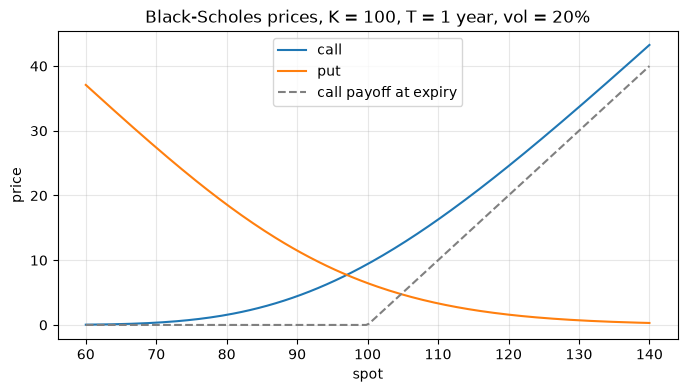

In [6]:
spots = np.linspace(60, 140, 200)
plt.figure(figsize=(8, 4))
plt.plot(spots, bs_price(spots, K, T, r, sigma, "call"), label="call")
plt.plot(spots, bs_price(spots, K, T, r, sigma, "put"), label="put")
plt.plot(spots, np.maximum(spots - K, 0), "--", color="grey", label="call payoff at expiry")
plt.xlabel("spot"); plt.ylabel("price")
plt.title("Black-Scholes prices, K = 100, T = 1 year, vol = 20%")
plt.legend(); plt.grid(alpha=0.3)
plt.show()